# Introduction

Code here is aimed at replicating Pettersen et al., 2025 (BioRxiv)

Here grid cells are obtained from a code which is distance preserving and capacity maximising:

$$\mathcal{L} = \alpha \mathbb{E}_{t,t'}\left[\exp\left( \frac{-||x_t-x_{t'}||^2}{2\sigma^2}\right)(||g(x_t)-g(x_{t'})|| - ||x_t-x_{t'}||)^2 \right] +(1-\alpha)\mathbb{E}_{t} \left[-\sum_{i}g_{i}(x_t) \right] $$


In [86]:
#setup 
import matplotlib.pyplot as plt
import ratinabox as riab
from tqdm import tqdm
import numpy as np
import torch
from importlib import reload

from GridModels.code.models import pettersen as pe # position encoder
from GridModels.code.measures import spatial
from GridModels.code.measures import gridcell_parameters as gparams
from GridModels.code.measures import grid_scorer
from GridModels.code.maze import representations as mr

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f'Using device: {DEVICE}')


Using device: cuda
Using device: cuda


## Train models

In [2]:
reload(pe)
options = pe.options
# SET OPTIONS #

options.trajectory_steps = 150000 #set to 150000 to load trajectories; otherwiseshould cover a 1.5x1.5 metre box
options.real_or_riab = 'mEC_2' #generated by ratinabox or loaded from a real trajectory?
options.maze_name_or_open_field = 'open_field' 

#model options:
options.distance_metric = 'euclidean'
options.alpha = 0.99 #the balance between distance loss and capacity loss
options.sigma = 1.7 #adjust the separation of points in distance loss
options.n_first_hidden = 64
options.n_second_hidden = 128
options.n_grid_cells = 256
options.initialisation = 'kaiming' #'kaiming' or 'xavier' or 'identity'
options.model_type = 'FF' # TODO: implementing the RNN as well?
 
#training options
options.batch_size = 128
options.train_steps = 50000
options.learning_rate = 5e-3
options.optimizer = 'AdamW' #'Adam' or 'AdamW' (the latter set to avoid implicit sparsity due to RELU activations)

  
model, losses, gridcell_metrics = pe.get_model_and_data(options)

Using device: cuda
Loading existing model and data!
Loading saved trajectory mEC_2.open_field.train.htsv


(array([ 5., 11., 18., 22., 21., 60., 46., 41., 28.,  4.]),
 array([-0.31540054, -0.2023216 , -0.08924266,  0.02383628,  0.13691522,
         0.24999416,  0.3630731 ,  0.47615204,  0.58923098,  0.70230992,
         0.81538886]),
 <BarContainer object of 10 artists>)

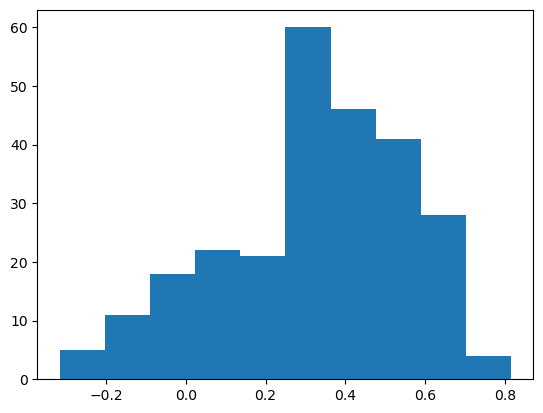

In [3]:
plt.hist(gridcell_metrics.gridscore)

### Training on many real trajectories



In [4]:
import pandas as pd
# save out real trajectory data 
from GridMaze.analysis.core import get_sessions as gs

open_field_sessions = gs.get_open_field_sessions(subject_IDs = ['mEC_2'],
                                           with_data = ['navigation_df'])

maze_sessions = gs.get_maze_sessions(subject_IDs = ['mEC_2'],
                                           maze_names = ['maze_1'],
                                           with_data = ['navigation_df'])

open_field_path = './GridModels/data/trajectories/mEC_2.open_field.train.htsv'
of_pos = pd.concat([x.navigation_df.centroid_position for x in open_field_sessions] )
of_pos = of_pos.dropna()
of_pos.columns = ['centroid_position.x','centroid_position.y']

maze_path = './GridModels/data/trajectories/mEC_2.maze_1.train.htsv'
maze_pos = pd.concat([x.navigation_df.centroid_position for x in maze_sessions])
maze_pos = maze_pos.dropna()
maze_pos.columns = ['centroid_position.x','centroid_position.y']

#save dfs
#of_pos.to_csv(open_field_path, sep='\t',index=False)
#maze_pos.to_csv(maze_path, sep = '\t', index = False)

Using device: cuda


In [5]:

import pandas as pd
from torch.utils.data import Dataset, DataLoader
reload(pe)

pe.DEVICE = 'cuda'
DEVICE = 'cuda'

all_pos = pd.concat([x.navigation_df.centroid_position for x in open_field_sessions],
                    columns = ['centroid_position.x','centroid_position.y'])
all_pos = all_pos.dropna()
class RealDataset(Dataset):
    def __init__(self, centroid_positions_df):
        self.positions = torch.tensor(centroid_positions_df.values,
                                      dtype=torch.float32)
    def __len__(self):
        return len(self.positions)
    def __getitem__(self, idx):
        return self.positions[idx]

dataset = RealDataset(all_pos)
plot_losses = True
options = pe.options
options.device = DEVICE
options.optimizer = 'AdamW'
options.learning_rate = 5e-3
options.batch_size = 128

#basically pasting code from train_model function here now

dataloader = DataLoader(dataset, batch_size=options.batch_size, shuffle=True)
# instantiate model
model = pe.PositionEncoder(positions_for_LUT = dataset.positions, 
                        distance_metric ='euclidean',
                        alpha=0.99, sigma=1.4,
                        hidden_1_size = options.first_hidden_size,
                        hidden_2_size = options.second_hidden_size,
                        output_size = options.n_grid_cells).to(DEVICE)

model.initialise_weights()
assert options.optimizer in ['Adam','AdamW']
if options.optimizer == 'Adam':
    optimizer = torch.optim.Adam(model.parameters(), lr=options.learning_rate)
elif options.optimizer == 'AdamW':
    optimizer = torch.optim.AdamW(model.parameters(), lr=options.learning_rate,
                                    weight_decay=0.0, amsgrad=True ) #prevent ReLU implicit  (https://arxiv.org/abs/1812.08119)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, patience = 1000, factor = 0.5)
losses = {'train':{'distance_losses':[],'capacity_losses':[]}}
n_pos= len(all_pos)
n_epochs = int(100000/(n_pos/options.batch_size))
positions_list = []
for i in range(n_epochs): #nepochs
    
    for positions in tqdm(dataloader):
        #total_loss = 0
        positions_list.append(positions)
        positions = positions.to(DEVICE)
        out = model(positions)

        distance_loss, capacity_loss = model.compute_losses(positions, out)
        loss = distance_loss + capacity_loss
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        #append losses for plotting
        losses['train']['distance_losses'].append(distance_loss.item())
        losses['train']['capacity_losses'].append(capacity_loss.item())
        #total_loss += loss.detach().cpu()
        scheduler.step(loss.item())
#scheduler.step(total_loss/len(dataloader))
if plot_losses:
    fig, ax = plt.subplots(1,2, figsize = (10,3))
    ax[0].set_title('encoding loss')
    ax[0].loglog(losses['train']['distance_losses'])
    ax[1].set_title('capacity loss')
    ax[1].plot(losses['train']['capacity_losses'])
    ax[1].set_xscale('log')
    plt.show()


Using device: cuda



KeyboardInterrupt



Using device: cuda
Computing Gridscores!


100%|██████████| 256/256 [00:06<00:00, 37.40it/s]


<Axes: xlabel='gridscore', ylabel='Count'>

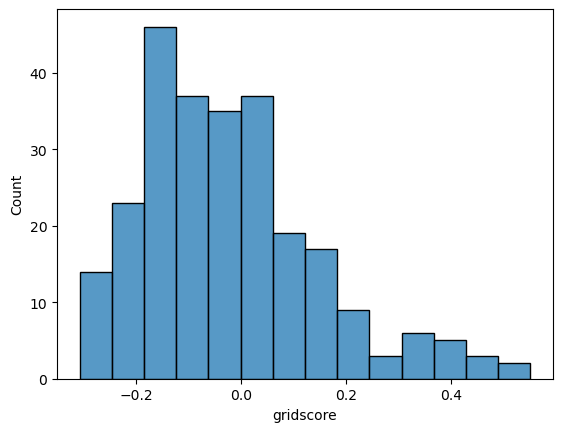

In [ ]:
#evaluate gridness
reload(pe)
gridcell_metrics_df = pe.get_gridcell_metrics_df(model)

import seaborn as sns
sns.histplot(gridcell_metrics_df,x='gridscore')

## Inspect trained models

Loading saved trajectory riab.open_field.test.htsv


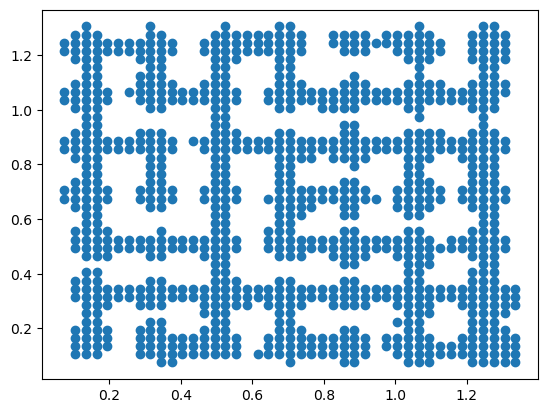

(256, 42, 42)


100%|██████████| 256/256 [00:06<00:00, 39.72it/s]


In [62]:
# have a look at ratemaps and grid cell matrix
from GridModels.code.measures import spatial
from GridModels.code.measures import grid_scorer; reload(grid_scorer)
from GridModels.code.maze import representations as mr
import networkx as nx
model.to(DEVICE)
dataset = pe.PositionDataset(train_or_test='test')

bin_size = 0.03

pixel_maze, bin_mask, meta = mr.get_pixel_maze(maze_pos, pixel_size = bin_size,
                                               return_bin_mask = True, return_meta = True)
x0,x1 = (meta['x0'],meta['x1'])
y0,y1 = (meta['y0'],meta['y1'])
pos = np.array([x for x in nx.get_node_attributes(pixel_maze,'position').values()])
plt.scatter(pos[:,0],pos[:,1])
plt.show()

with torch.no_grad():
    hidden_activations = model(torch.tensor(pos).to(dtype=torch.float32,
                                                    device=DEVICE))
    
ratemaps, binx, biny = spatial.get_2D_ratemaps(hidden_activations.cpu().numpy(),
                                               pos,
                                               smooth_SD=0.0, 
                                               x_size = bin_size, 
                                               y_size = bin_size,
                                               x_range = (x0,x1),
                                               y_range = (y0,y1))

def pad_ratemaps_and_bins_np(maps, binx, biny):
    """
    maps: (n_neurons, n_xbins, n_ybins) float array
    binx, biny: 1D arrays of bin centers (len nx, ny)
    Returns: maps_sq (n, S, S), binx_S (S,), biny_S (S,)
    - Pads maps with NaNs, centered.
    - Extrapolates the shorter bin list on both ends to reach S.
    """
    assert maps.ndim == 3
    n, nx, ny = maps.shape
    S = max(nx, ny)
    out = np.full((n, S, S), np.nan, dtype=maps.dtype if np.issubdtype(maps.dtype, np.floating) else np.float32)

    # where to place the original data (center)
    x0 = (S - nx) // 2; x1 = x0 + nx
    y0 = (S - ny) // 2; y1 = y0 + ny
    out[:, x0:x1, y0:y1] = maps

    def _extrapolate(b, target_len):
        if len(b) == target_len: return b.copy()
        need = target_len - len(b)
        return np.concatenate([b, np.repeat([np.nan],need)])
    target_len = np.max([len(binx),len(biny)])
    binx_S = _extrapolate(np.asarray(binx), target_len)
    biny_S = _extrapolate(np.asarray(biny), target_len)
    return out, binx_S, biny_S

ratemaps, binx, biny = pad_ratemaps_and_bins_np(ratemaps,binx,biny)
print(ratemaps.shape)
gridcell_metrics = grid_scorer.get_grid_scores(ratemaps,binx,biny,
                                               return_metrics=True)


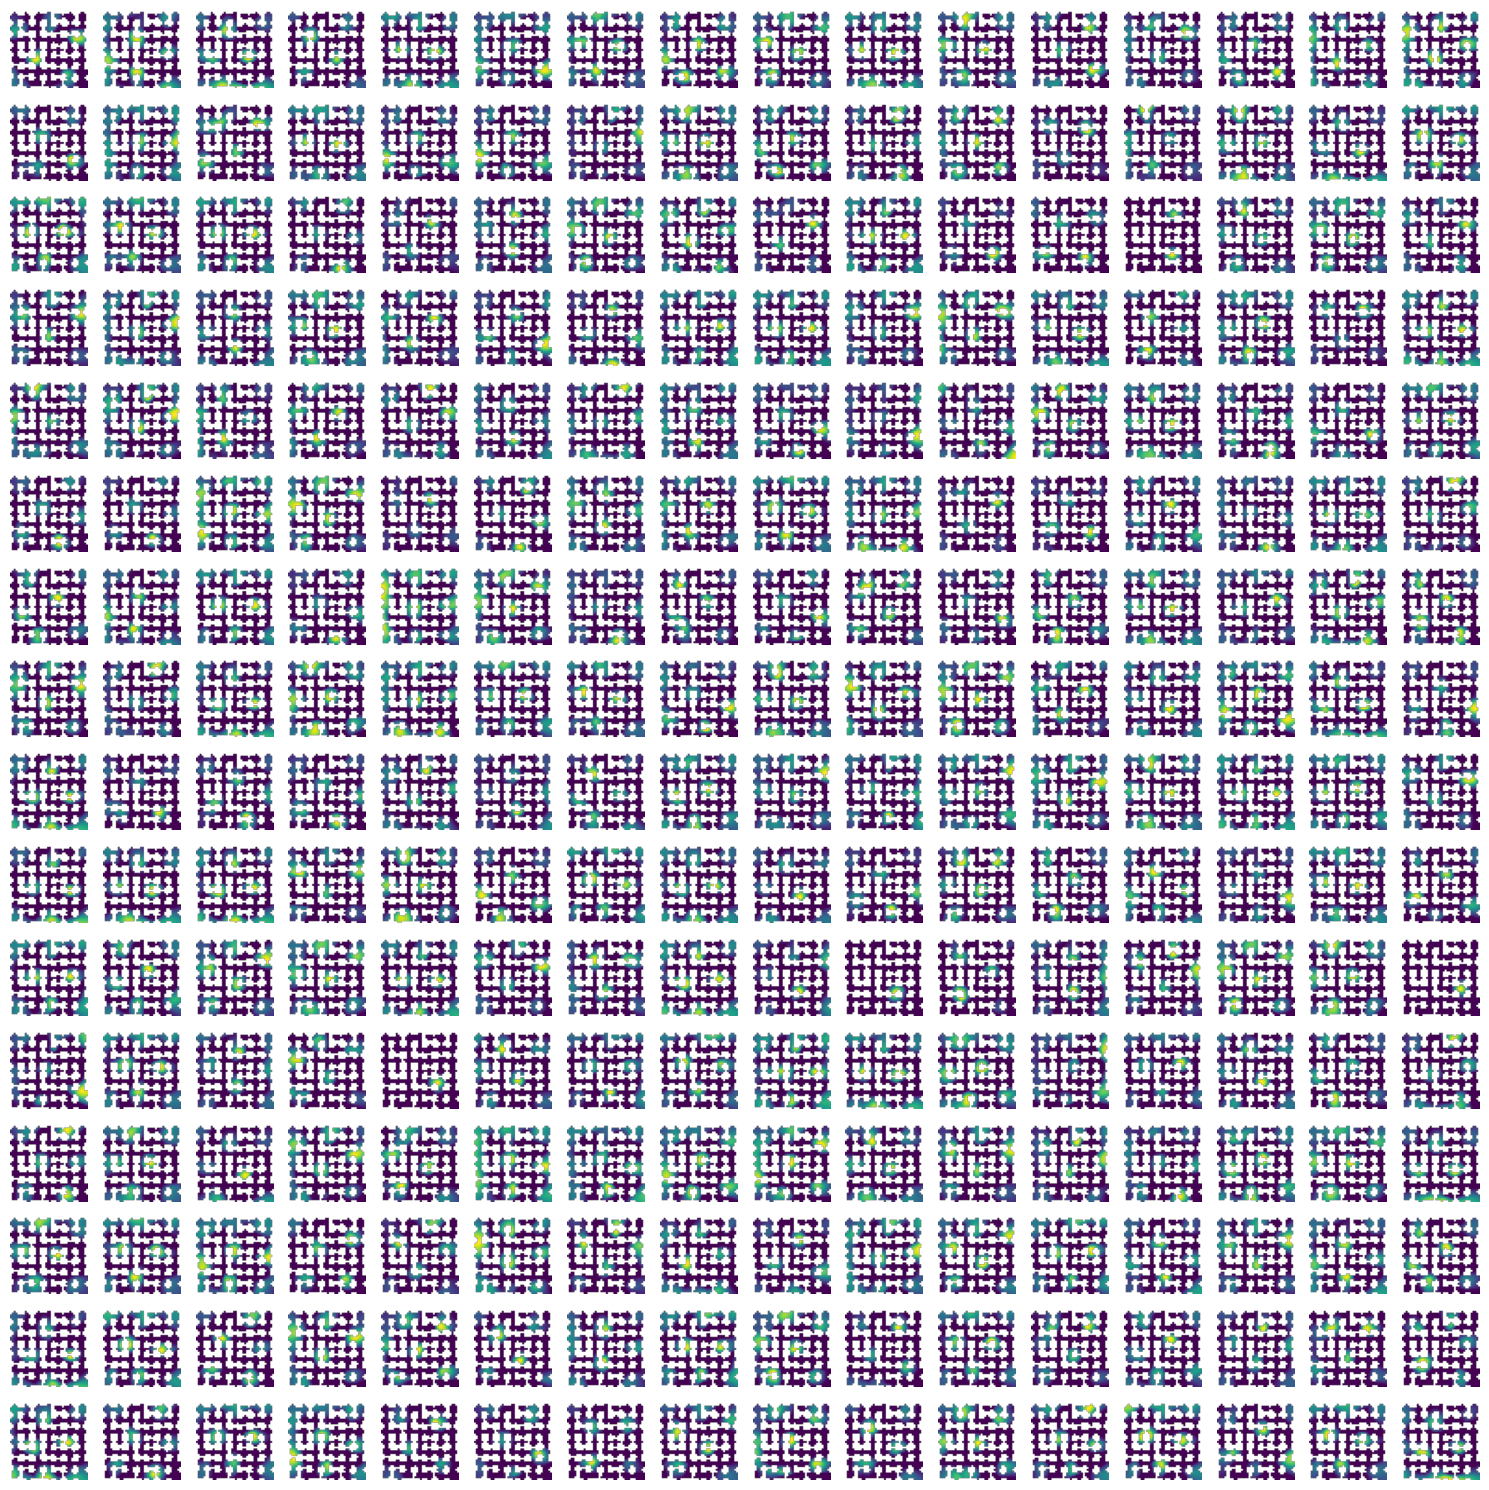

In [63]:
fig, axes = plt.subplots(16, 16, figsize=(15, 15))
for i, ax in enumerate(axes.flat):
    if i < ratemaps.shape[0]:
        ax.imshow(ratemaps[i], aspect='auto', origin='lower')
    ax.set_xticks([])
    ax.set_yticks([])
    ax.axis('off')
plt.tight_layout()
plt.show()

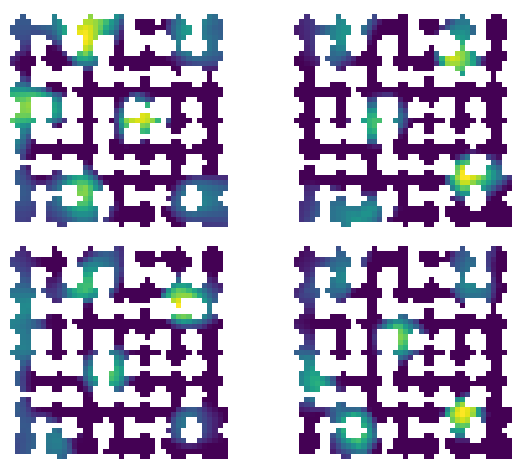

In [64]:
# plot a subset of 4 units:
fig, ax = plt.subplots(2,2)
for i, axis in enumerate(ax.flatten()):
    axis.imshow(ratemaps[10+i], origin='lower')
    axis.axis('off')
fig.tight_layout()

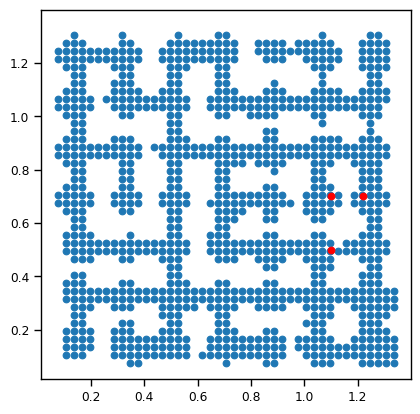

tensor([2.1000, 1.2000, 2.4187])

In [ ]:
#test the distance between points on the maze
test_pos = torch.tensor([[1.1,0.7],[1.1,0.5],[1.22,0.7]])
plt.scatter(pos[:,0],pos[:,1])
plt.scatter(test_pos[:,0],test_pos[:,1],c='r')
plt.axis('square')
plt.show()

model.LUT_pdist(test_pos.to(DEVICE))


Using device: cuda
0.63


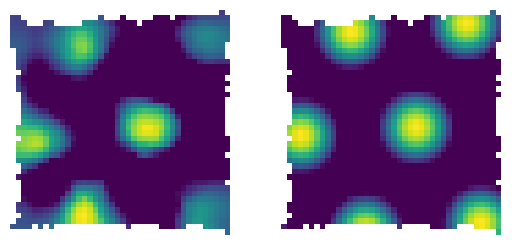

In [59]:
#check parameter estimation / fit
from GridMaze.analysis.metrics import get_grid_params as gparams
reload(gparams)
fit = gparams.fit_hexagonal_model2ratemap(ratemaps[10],pe.LUT_BIN_SIZE)
fig, ax = plt.subplots(1,2)
ax[0].imshow(ratemaps[10])
ax[1].imshow(fit['fitted_ratemap'])
[x.axis('off') for x in ax]
print(fit['scale'])

2 2
1 1
(40, 40)


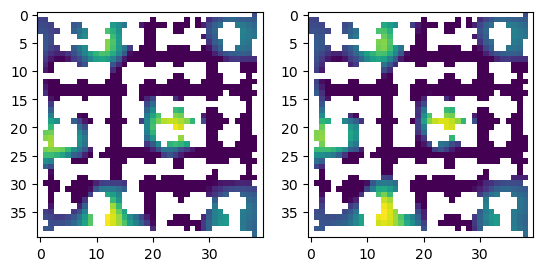

In [ ]:
masked_of_rm, cropped_maze_rm = spatial.get_aligned_ratemaps(of_ratemap,maze_ratemap)
fig, ax = plt.subplots(1,2)
ax[0].imshow(masked_of_rm)
ax[1].imshow(cropped_maze_rm)

Using device: cuda
0.63
0.6


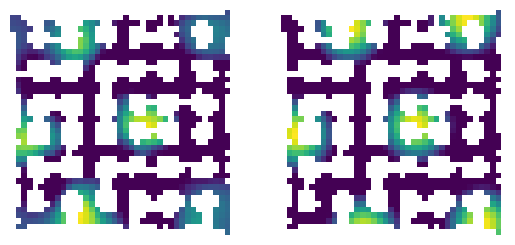

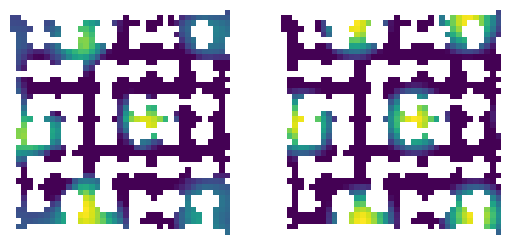

In [84]:
from GridMaze.analysis.metrics import get_grid_params as gparams
reload(gparams)
for each_ratemap in [masked_of_rm,cropped_maze_rm]:
    fit = gparams.fit_hexagonal_model2ratemap(each_ratemap,pe.LUT_BIN_SIZE)
    fig, ax = plt.subplots(1,2)
    ax[0].imshow(each_ratemap)
    ax[1].imshow(fit['fitted_ratemap'])
    [x.axis('off') for x in ax]
    print(fit['scale'])
    fig.show()

[Text(0.5, 0, 'orientation (deg)')]

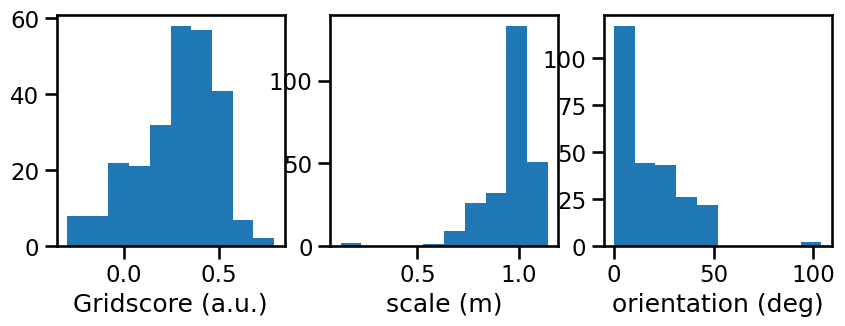

In [123]:
import seaborn as sns

fig, ax = plt.subplots(1,3, figsize = (10,3))
ax[0].hist(gridcell_metrics['gridscore'])
ax[0].set(xlabel='Gridscore (a.u.)')
ax[1].hist(gridcell_metrics['scale'])
ax[1].set(xlabel='scale (m)')
ax[2].hist(gridcell_metrics['orientation'])
ax[2].set(xlabel='orientation (deg)')

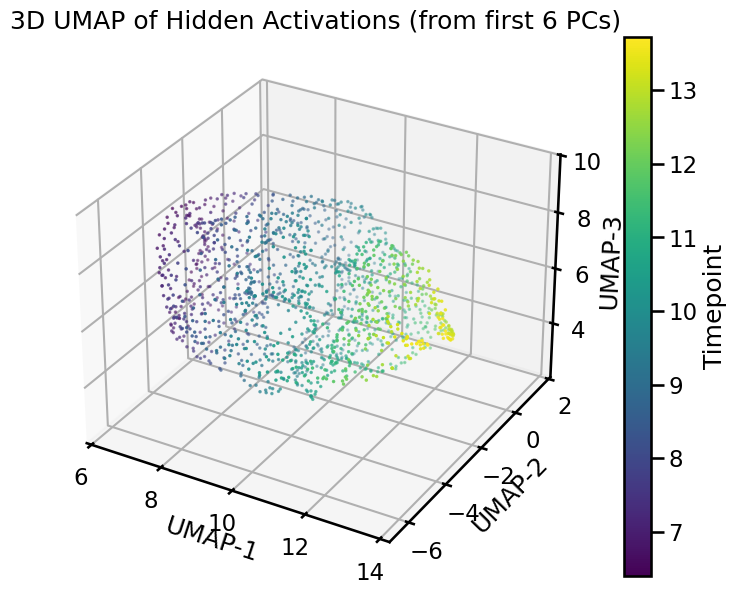

In [132]:
import umap
from mpl_toolkits.mplot3d import Axes3D
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

# Move hidden_activations to CPU and convert to numpy
hidden_np = hidden_activations.cpu().numpy()

# First reduce dimensionality with PCA to 6 components
pca = PCA(n_components=6)
hidden_pca = pca.fit_transform(hidden_np)

# Print explained variance ratio
#print("Explained variance ratio of first 6 PCs:", pca.explained_variance_ratio_)
#print("Cumulative explained variance:", np.sum(pca.explained_variance_ratio_))

# Then apply UMAP to the PCA results
umap_3d = umap.UMAP(n_components=3, 
                    n_neighbors = 100,
                    min_dist = 0.5,
                    n_jobs=4)

hidden_umap = umap_3d.fit_transform(hidden_np)

# Interactive 3D scatter plot
fig = plt.figure(figsize=(10, 7))
ax3d = fig.add_subplot(111, projection='3d')
sc = ax3d.scatter(hidden_umap[:, 0], hidden_umap[:, 1], hidden_umap[:, 2],
                  c=hidden_umap[:,0], cmap='viridis', s=1)
plt.colorbar(sc, label='Timepoint')
ax3d.set_xlabel('UMAP-1')
ax3d.set_ylabel('UMAP-2')
ax3d.set_zlabel('UMAP-3')
plt.title('3D UMAP of Hidden Activations (from first 6 PCs)')
plt.show()

In [133]:
import plotly.graph_objs as go
import plotly.io as pio

# Create a 3D scatter plot using plotly
trace = go.Scatter3d(
    x=hidden_umap[:, 0],
    y=hidden_umap[:, 1],
    z=hidden_umap[:, 2],
    mode='markers',
    marker=dict(
        size=2,
        color=np.arange(hidden_umap.shape[0]), # color by timepoint
        colorscale='Viridis',
        opacity=0.8,
        colorbar=dict(title='Timepoint')
    )
)

layout = go.Layout(
    scene=dict(
        xaxis_title='UMAP-1',
        yaxis_title='UMAP-2',
        zaxis_title='UMAP-3'
    ),
    title='3D UMAP of Hidden Activations (Plotly Interactive)'
)

fig_plotly = go.Figure(data=[trace], layout=layout)
pio.show(fig_plotly)

# Alpha and sigma parameter search


In [ ]:
#UNCOMMENT BELOW TO SEND MANY JOBS TO A CLUSTER
from Jobs.pettersen_parameters import gridsearch_alpha_sigma as gas; 
from importlib import reload; reload(gas)
#gas.do_gridsearch()

Submitted batch job 1264542
Submitted job for alpha 0.01 sigma 1.0 to HPC. 
Submitted batch job 1264543
Submitted job for alpha 0.01 sigma 1.3 to HPC. 
Submitted batch job 1264544
Submitted job for alpha 0.01 sigma 1.7 to HPC. 
Submitted batch job 1264545
Submitted job for alpha 0.01 sigma 2.2 to HPC. 
Submitted batch job 1264546
Submitted job for alpha 0.01 sigma 2.8 to HPC. 
Submitted batch job 1264547
Submitted job for alpha 0.01 sigma 3.6 to HPC. 
Submitted batch job 1264548
Submitted job for alpha 0.01 sigma 4.6 to HPC. 
Submitted batch job 1264549
Submitted job for alpha 0.01 sigma 6.0 to HPC. 
Submitted batch job 1264550
Submitted job for alpha 0.01 sigma 7.7 to HPC. 
Submitted batch job 1264551
Submitted job for alpha 0.01 sigma 10.0 to HPC. 
Submitted batch job 1264552
Submitted job for alpha 0.1 sigma 1.0 to HPC. 
Submitted batch job 1264553
Submitted job for alpha 0.1 sigma 1.3 to HPC. 
Submitted batch job 1264554
Submitted job for alpha 0.1 sigma 1.7 to HPC. 
Submitted batc

In [2]:
## Let's inspect the many models
import re
import pandas as pd
from Jobs.pettersen_parameters import gridsearch_alpha_sigma as gas; 
reload(gas)
model_type = 'FF'
environment = 'open_field'
df_dict= {'alpha':[],'sigma':[],'lr':[], 'metric':[], 'environment':[],
          'mean_gridscore':[],'median_gridscore':[],'max_gridscore':[]}

alphas = [str(x) for x in gas.ALPHAS]
sigmas = [str(x) for x in gas.SIGMAS]

for i,env_dir in enumerate((pe.MODELS_DIR/model_type).iterdir()):
    environment = env_dir.stem
    for metric_dir in env_dir.iterdir():
        metric = metric_dir.stem
        for subdir in metric_dir.iterdir():
            s = subdir.__str__().split('/')[-1]

            # Split by period followed by letter, then split each part by underscore
            parts = re.split(r'\.(?=[a-zA-Z])', s)
            params = dict(part.split('_') for part in parts)

            if params['alpha'] not in alphas or params['sigma'] not in sigmas:
                continue
            for k,v in params.items():
                df_dict[k].append(v)
            gridcell_metrics = pd.read_csv(subdir/'gridcell_metrics.htsv', sep='\t')
            df_dict['mean_gridscore'].append(gridcell_metrics.gridscore.mean())
            df_dict['median_gridscore'].append(gridcell_metrics.gridscore.median())
            df_dict['max_gridscore'].append(gridcell_metrics.gridscore.max())
            df_dict['environment'].append(environment)
            df_dict['metric'].append(metric)
gridscore_df = pd.DataFrame(df_dict)

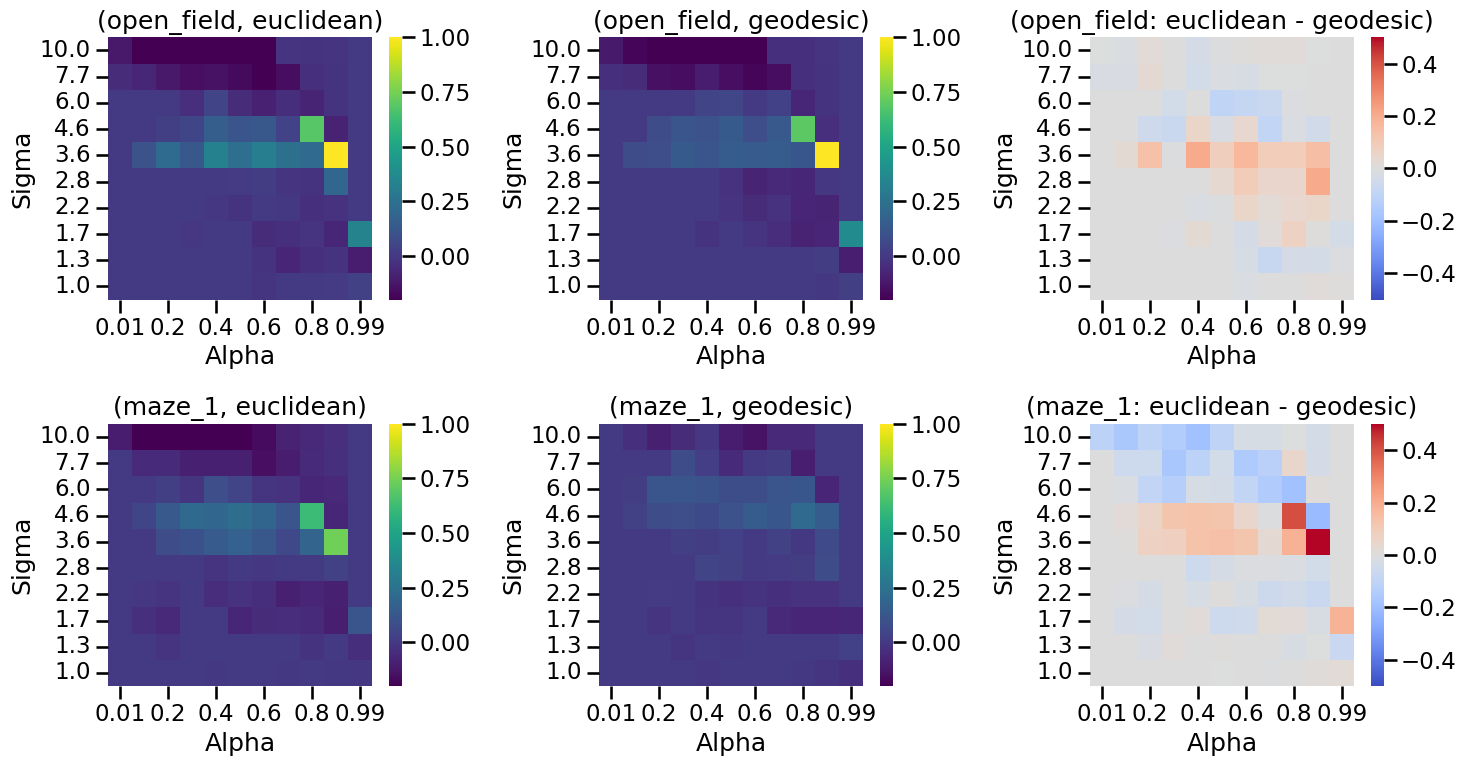

In [3]:
import seaborn as sns
sns.set_context('talk')
gridscore_df['alpha'] = pd.to_numeric(gridscore_df['alpha'])
gridscore_df['sigma'] = pd.to_numeric(gridscore_df['sigma'])

environments = ['open_field','maze_1']
metric_types = ['euclidean','geodesic']

fig, axes = plt.subplots(len(environments), 3, 
                        figsize=(15, 4*len(environments)),
                        squeeze=False)

vmin = gridscore_df['median_gridscore'].min()
vmax = gridscore_df['median_gridscore'].max()

for row, env in enumerate(environments):
    env_df = gridscore_df.query('environment == @env')
    pivots = []
    for metric_type in metric_types:
        pivot = env_df.query('metric == @metric_type').pivot_table(
            values='median_gridscore', index='sigma', columns='alpha', aggfunc='mean')
        pivots.append(pivot)
    
    # Plot the two metrics
    for col in range(2):
        ax = axes[row, col]
        if pivots[col].notna().sum().sum() > 0:
            sns.heatmap(pivots[col].iloc[::-1], ax=ax, cmap='viridis', 
                        cbar=True,
                        vmin = -0.2, vmax = 1)
        else:
            ax.set_visible(False)
        ax.set_title(f'({env}, {metric_types[col]})')
        ax.set_xlabel('Alpha')
        ax.set_ylabel('Sigma')
    
    # Plot the difference
    diff = pivots[0] - pivots[1]
    ax = axes[row, 2]
    if diff.notna().sum().sum() > 0:
        sns.heatmap(diff.iloc[::-1], ax=ax, cmap='coolwarm', 
                    annot=False, fmt=".2f", cbar=True,
                    vmin = -0.5, vmax = 0.5)
    else:
        ax.set_visible(False)
    ax.set_title(f'({env}: {metric_types[0]} - {metric_types[1]})')
    ax.set_xlabel('Alpha')
    ax.set_ylabel('Sigma')
    

plt.tight_layout()
plt.show()

# Grid parameter estimation

We estimated grid scale and orientation by fitting a hexagonal (rectified cosine) model to the ratemaps.
The goodness-of-fit is measured by a correlation value (we take the maximal as the 'fitted' parameters).


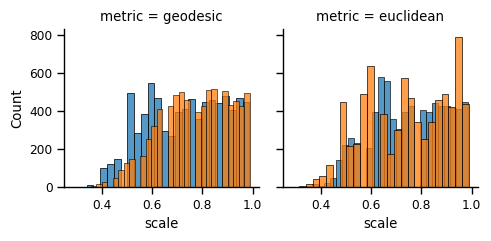

In [39]:
filepath = '../results/gridcells/pettersen_grid_params.htsv'
pet_param_df = pd.read_csv(filepath,sep='\t')
sns.set_context('paper')
filtered_df = pet_param_df.query('fit_corr>0.5 and scale < 1.0')
g = sns.FacetGrid(filtered_df, col = 'metric', height = 2.5, hue = 'environment')
g.map(sns.histplot, 'scale')
g.tight_layout()


In [ ]:
fig, ax = plt.subplots(1,2)
sns.histplot(filtered_df.query('metric=="geodesic"'))

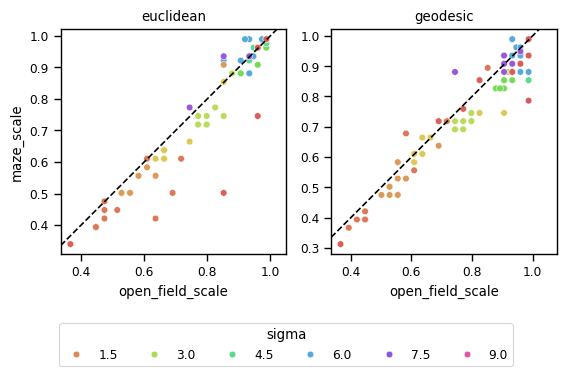

In [134]:
plot_dict = {'sigma':[],'alpha':[],'metric':[],'maze_scale':[],'open_field_scale':[]}
for each_sigma in filtered_df.sigma.unique():
    for each_alpha in filtered_df.alpha.unique():
        for each_metric in ['geodesic','euclidean']:
            subdf = filtered_df.query(f'sigma=={each_sigma} and alpha == {each_alpha}')
            mean_scale_df = subdf.groupby(['metric','environment']).median('scale')
            try:
                maze_scale = mean_scale_df.loc[f'{each_metric}','maze_1'].scale
                open_field_scale = mean_scale_df.loc[f'{each_metric}','open_field'].scale        
            except:
                maze_scale = np.nan
                open_field_scale = np.nan
            #append stuff
            plot_dict['maze_scale'].append(maze_scale)
            plot_dict['open_field_scale'].append(open_field_scale)
            plot_dict['sigma'].append(each_sigma)
            plot_dict['alpha'].append(each_alpha)
            plot_dict['metric'].append(each_metric)

#make df and plot!
plot_df = pd.DataFrame(plot_dict)
fig, ax = plt.subplots(1,2)
sns.scatterplot(plot_df.query('metric=="euclidean"'), 
                x= 'open_field_scale',y='maze_scale', 
                hue ='sigma', ax = ax[0], palette = 'hls')
ax[0].set(title = 'euclidean',xlim=(0.3,1),ylim=(0.3,1))
ax[0].legend(loc = 'center',ncols=6,bbox_to_anchor= (1.0,-0.4),
             title = 'sigma')
sns.scatterplot(plot_df.query('metric=="geodesic"'), 
                x= 'open_field_scale',y='maze_scale', 
                hue ='sigma', ax = ax[1],palette = 'hls',
                legend=False)
ax[1].set(title = 'geodesic',xlim=(0.3,1),ylim=(0.3,1),ylabel='')
[x.axis('square') and x.axline((0,0), (1,1), color='black', linestyle='--') for x in ax]


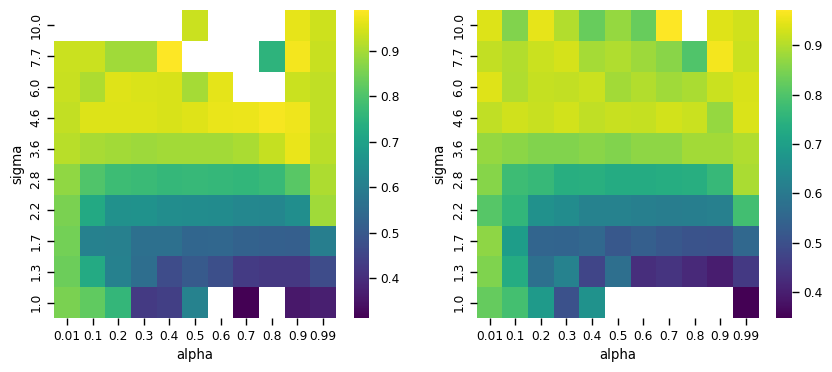

In [142]:
fig, ax = plt.subplots(1,2, figsize = (10,4))

pivots = []
for metric_type in metric_types:
    pivot = filtered_df.query('metric == @metric_type').pivot_table(
        values='scale', index='sigma', columns='alpha', aggfunc='mean')
    pivots.append(pivot)

# Plot the two metrics
for col in range(2):
    axis = ax[col]
    if pivots[col].notna().sum().sum() > 0:
        sns.heatmap(pivots[col].iloc[::-1], ax=axis, cmap='viridis', 
                    cbar=True)
        


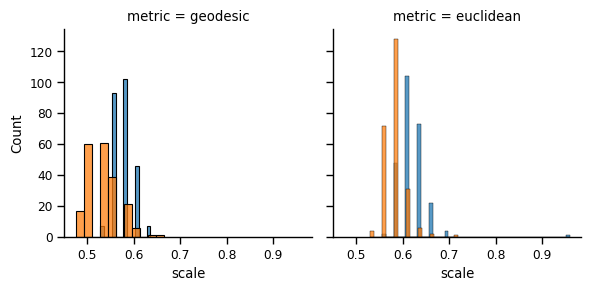

In [152]:
test_df = filtered_df.query('alpha==0.99 and sigma ==1.7')
g = sns.FacetGrid(test_df, col = 'metric',hue = 'environment')
g.map(sns.histplot, 'scale')

### debugging

The above result is unexpected. There should not be a scale difference between maze and open field for a euclidean maze.

Let's take a closer look. Here are possible bugs:

1. ratemap size differences causing differences in scale estimates
2. 

#### 1. euclidean open field model on maze data

In [ ]:
## First sanity check: 
# model trained on euclidean distance open field 
# should have same scale when evaluated on maze data
options = pe.options
#main options specification
options.maze_name_or_open_field = 'open_field'
options.distance_metric = 'euclidean'
options.alpha = 0.99
options.sigma = 1.7
#get model
model, losses, gridcell_metrics = pe.get_model_and_data(options)
model.eval()
#get data
maze_data = pe.PositionDataset(real_or_riab='mEC_2', maze_name_or_open_field = 'maze_1')
box_data = pe.PositionDataset(real_or_riab='mEC_2',maze_name_or_open_field='open_field')



Loading existing model and data!
Loading saved trajectory mEC_2.open_field.train.htsv
Loading saved trajectory mEC_2.maze_1.train.htsv
Loading saved trajectory mEC_2.open_field.train.htsv


In [ ]:
#run through the datasets and store the relevant parameters
data_dict = {'open_field':{},'maze':{}}
for environment in data_dict.keys():
    if environment == 'open_field':
        pos = box_data.positions
    elif environment == 'maze':
        pos = maze_data.positions
    #run through
    with torch.no_grad():
        hidden_activations = model(pos)
    ratemaps, binx, biny = spatial.get_2D_ratemaps(hidden_activations.cpu().numpy(),
                                                    pos.cpu().numpy())
    ratemaps, binx, biny = pe.pad_ratemaps_and_bins_np(ratemaps, binx, biny) #see utility function at bottom of script
    data_dict[environment]['ratemaps'] = ratemaps
    scales = []
    fit_rms = []
    for ratemap in ratemaps:
        fit = gparams.fit_hexagonal_model2ratemap(ratemap, pe.LUT_BIN_SIZE, device = pe.DEVICE)
        scales.append(fit['scale'])     
        fit_rms.append(fit['fitted_ratemap'])
    data_dict[environment]['fit_ratemaps'] = np.stack(fit_rms)
    data_dict[environment]['scale'] = scales
        
fig, ax = plt.subplots()
ax.scatter(data_dict['open_field']['scale'],
            data_dict['maze']['scale'],
            )
ax.axline((0,0),(1,1))

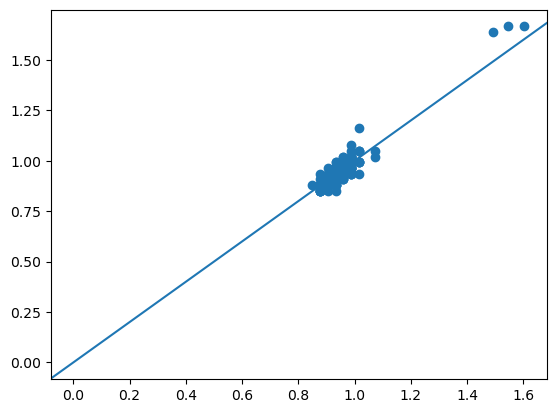

In [97]:
fig, ax = plt.subplots()
ax.scatter(data_dict['open_field']['scale'],
            data_dict['maze']['scale'],
            )
ax.axline((0,0),(1,1))

#### 2. maze vs open field with euclidean metric

Loading existing model and data!
Loading saved trajectory mEC_2.maze_1.train.htsv
Loading existing model and data!
Loading saved trajectory mEC_2.open_field.train.htsv


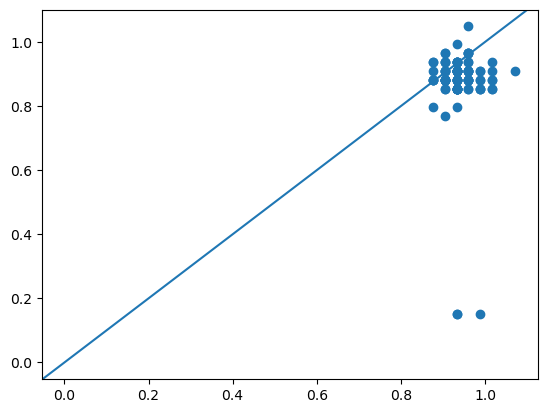

In [102]:
#run through the datasets and store the relevant parameters
data_dict = {'open_field':{},'maze':{}}
for environment in ['maze','open_field']: #data_dict.keys():
    if environment == 'open_field':
        options.maze_name_or_open_field = 'open_field'
        model, losses, gridcell_metrics = pe.get_model_and_data(options)

        pos = box_data.positions
    elif environment == 'maze':
        pos = maze_data.positions
        options.maze_name_or_open_field = 'maze_1'
        model, losses, gridcell_metrics = pe.get_model_and_data(options)

    #run through
    with torch.no_grad():
        hidden_activations = model(pos)
    ratemaps, binx, biny = spatial.get_2D_ratemaps(hidden_activations.cpu().numpy(),
                                                    pos.cpu().numpy())
    ratemaps, binx, biny = pe.pad_ratemaps_and_bins_np(ratemaps, binx, biny) #see utility function at bottom of script
    data_dict[environment]['ratemaps'] = ratemaps
    scales = []
    fit_rms = []
    for ratemap in ratemaps[:100]:
        fit = gparams.fit_hexagonal_model2ratemap(ratemap, pe.LUT_BIN_SIZE, device = pe.DEVICE)
        scales.append(fit['scale'])     
        fit_rms.append(fit['fitted_ratemap'])
    data_dict[environment]['fit_ratemaps'] = np.stack(fit_rms)
    data_dict[environment]['scale'] = scales
        
        
fig, ax = plt.subplots()
ax.scatter(data_dict['open_field']['scale'],
            data_dict['maze']['scale'],
            )
ax.axline((0,0),(1,1))

(array([ 8.,  0., 20.,  0.,  0., 36.,  0.,  0., 21.,  0.,  0.,  8.,  0.,
         0.,  6.,  0.,  0.,  0.,  0.,  1.]),
 array([0.87620687, 0.88598274, 0.8957586 , 0.90553446, 0.91531032,
        0.92508618, 0.93486204, 0.9446379 , 0.95441376, 0.96418962,
        0.97396548, 0.98374134, 0.9935172 , 1.00329307, 1.01306893,
        1.02284479, 1.03262065, 1.04239651, 1.05217237, 1.06194823,
        1.07172409]),
 <BarContainer object of 20 artists>)

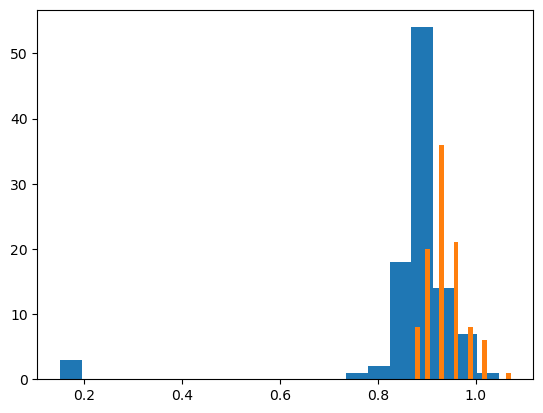

In [105]:
plt.hist(data_dict['maze']['scale'], bins = 20)
plt.hist(data_dict['open_field']['scale'], bins = 20)

In [ ]:
maze_scales = np.array(data_dict['maze']['scale'])
field_scales = np.array(data_dict['open_field']['scale'])



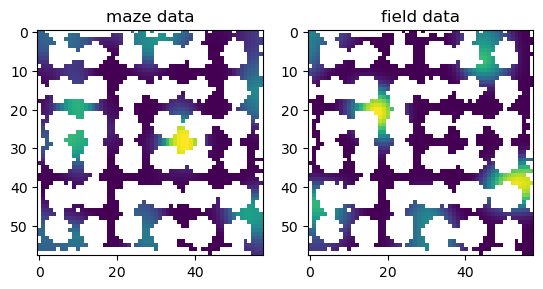

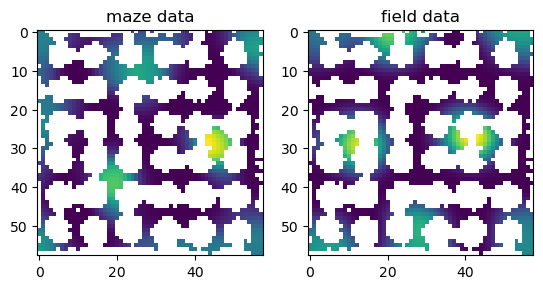

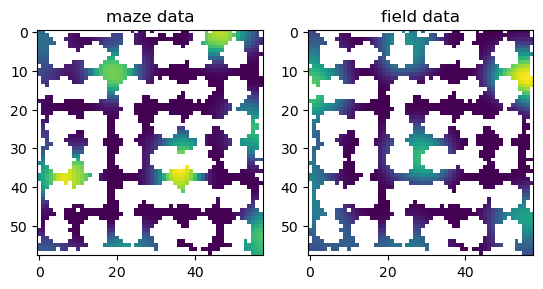

In [132]:
smaller_indices = [x for x in np.argwhere(maze_scales<field_scales)]

for idx in smaller_indices[:3]:
    fig, ax = plt.subplots(1,2)
    maze_rm = data_dict['maze']['ratemaps'][idx].squeeze()
    field_rm = data_dict['open_field']['ratemaps'][idx].squeeze()
    masked_field, cropped_maze = spatial.get_aligned_ratemaps(field_rm,maze_rm)
    ax[0].imshow(cropped_maze)
    ax[0].set(title = 'maze data')
    ax[1].imshow(masked_field)
    ax[1].set(title = 'field data')
    
    fig.show()

In [111]:
print(maze_data.positions.min(),maze_data.positions.max())
print(box_data.positions.min(),box_data.positions.max())

tensor(0.0610, device='cuda:0') tensor(1.3495, device='cuda:0')
tensor(0.0862, device='cuda:0') tensor(1.2816, device='cuda:0')
